<a href="https://colab.research.google.com/github/samsyed004/CV-lab/blob/main/FA23_BAI_007_LabMid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Mid Exam (HOG vs SIFT on Blood-Cell Images)

**Registration number: FA23-BAI-007**  

## Personal settings

In [ ]:
REG_NO = "007"                                   # <- registration number

SEED = int(REG_NO[-2:])                          # last two digits            -> 07 -> 7
last_digit = int(REG_NO[-1])                     # last digit                 -> 7
HOG_CELL = 8 if last_digit % 2 == 0 else 16      # even -> 8x8, odd -> 16x16  -> 16
SIFT_GRID = 4 if last_digit <= 4 else 6          # 0-4 -> 4x4, 5-9 -> 6x6     -> 6

print(f"Registration number : {REG_NO}")
print(f"Random seed         : {SEED}")
print(f"HOG cell size       : {HOG_CELL} x {HOG_CELL}  (last digit {last_digit} is {'even' if last_digit % 2 == 0 else 'odd'})")
print(f"SIFT grid size      : {SIFT_GRID} x {SIFT_GRID} = {SIFT_GRID ** 2} keypoints  (last digit {last_digit})")

Registration number : 007
Random seed         : 7
HOG cell size       : 16 x 16  (last digit 7 is odd)
SIFT grid size      : 6 x 6 = 36 keypoints  (last digit 7)


In [ ]:
!pip install -q medmnist scikit-image opencv-python-headless

In [ ]:
import warnings, numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(SEED)

# ---- fixed settings (same for everyone) ----
KEEP_IDS = [1, 5, 6, 7]                                    # BloodMNIST label ids
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}
IMG = 128
HOG_ORIENT, HOG_BLOCK = 9, (2, 2)
C_GRID = [0.1, 1, 10]
ROT_ANGLE, NOISE_SIGMA = 20, 0.05

# Q1. Data setup

In [ ]:
import medmnist
from medmnist import BloodMNIST, INFO

print("BloodMNIST labels:", INFO["bloodmnist"]["label"])

rng = np.random.default_rng(SEED)            # one generator -> subset is fixed by the seed
raw = {}                                     # split -> (images 64x64x3 uint8, labels 0..3)
for split in ["train", "val", "test"]:
    ds = BloodMNIST(split=split, download=True, size=64)
    imgs, labs = ds.imgs, ds.labels.ravel()
    chosen_x, chosen_y = [], []
    for new_label, cid in enumerate(KEEP_IDS):
        idx = np.flatnonzero(labs == cid)
        pick = np.sort(rng.choice(idx, N_PER_CLASS[split], replace=False))
        chosen_x.append(imgs[pick]); chosen_y.append(np.full(len(pick), new_label))
    raw[split] = (np.concatenate(chosen_x), np.concatenate(chosen_y))

# image preparation: grayscale, resize to 128 x 128
def prepare(img_rgb):
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.resize(g, (IMG, IMG), interpolation=cv2.INTER_CUBIC)

X, y = {}, {}
for split, (im, lb) in raw.items():
    X[split] = np.stack([prepare(a) for a in im]).astype(np.uint8)
    y[split] = lb

rows = []
for split in ["train", "val", "test"]:
    print(f"{split:5s} | raw images {raw[split][0].shape} -> prepared images {X[split].shape} | labels {y[split].shape}")
    rows.append({"split": split, **{CLASS_NAMES[k]: int((y[split] == k).sum()) for k in range(4)}, "total": len(y[split])})
pd.DataFrame(rows).set_index("split")

BloodMNIST labels: {'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}
train | raw images (400, 64, 64, 3) -> prepared images (400, 128, 128) | labels (400,)
val   | raw images (120, 64, 64, 3) -> prepared images (120, 128, 128) | labels (120,)
test  | raw images (120, 64, 64, 3) -> prepared images (120, 128, 128) | labels (120,)


,eosinophil,monocyte,neutrophil,platelet,total
split,,,,,
train,100,100,100,100,400
val,30,30,30,30,120
test,30,30,30,30,120


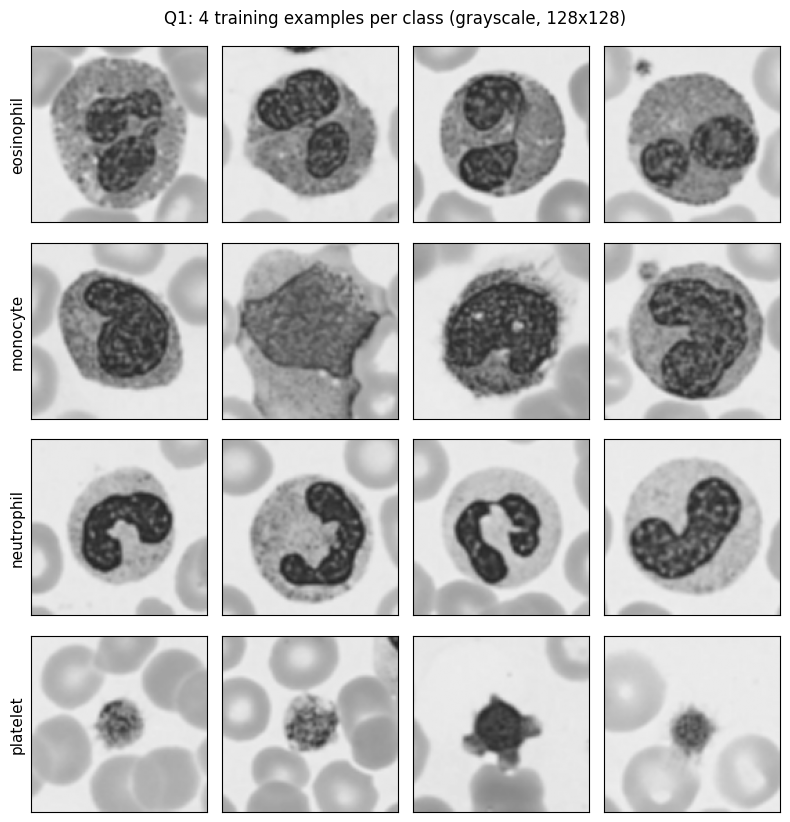

In [ ]:
# one grid: 4 example images per class (prepared 128x128 grayscale training images)
fig, axes = plt.subplots(4, 4, figsize=(8, 8.4))
for r in range(4):
    idx = np.flatnonzero(y["train"] == r)[:4]
    for c in range(4):
        axes[r][c].imshow(X["train"][idx[c]], cmap="gray", vmin=0, vmax=255); axes[r][c].set_xticks([]); axes[r][c].set_yticks([])
    axes[r][0].set_ylabel(CLASS_NAMES[r], fontsize=11)
plt.suptitle("Q1: 4 training examples per class (grayscale, 128x128)"); plt.tight_layout(); plt.show()

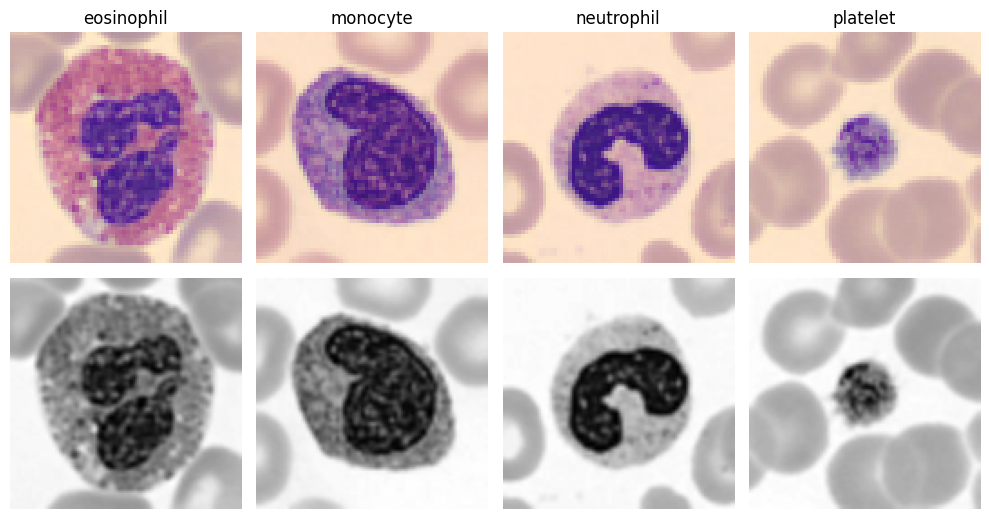

In [ ]:
# supporting picture for Q5: original colour vs prepared grayscale (first training image of each class)
fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
for k in range(4):
    i = np.flatnonzero(y["train"] == k)[0]
    axes[0][k].imshow(raw["train"][0][i]); axes[0][k].set_title(CLASS_NAMES[k]); axes[1][k].imshow(X["train"][i], cmap="gray")
    axes[0][k].axis("off"); axes[1][k].axis("off")
axes[0][0].set_ylabel("colour"); axes[1][0].set_ylabel("grayscale")
plt.tight_layout(); plt.show()

# Q2. HOG + SVM

### Q2(a) HOG feature length

Settings: image 128 × 128, cell 16 × 16, 2 × 2 cells per block, 9 orientations, block stride = 1 cell.

* Cells per side = 128 / 16 = **8**  →  8 × 8 = 64 cells
* Blocks per side (2 × 2 cells, stride 1 cell) = 8 − 2 + 1 = **7**  →  7 × 7 = **49 blocks**
* Values per block = 2 × 2 cells × 9 orientations = **36**
* Feature length = 49 blocks × 36 = **1764**

The code below extracts the features and checks this number.

In [ ]:
def hog_feat(img_u8):
    return hog(img_u8.astype(np.float32) / 255.0, orientations=HOG_ORIENT,
               pixels_per_cell=(HOG_CELL, HOG_CELL), cells_per_block=HOG_BLOCK,
               block_norm="L2-Hys", feature_vector=True)

def hog_features(imgs):
    return np.array([hog_feat(i) for i in imgs], dtype=np.float32)

F_hog = {s: hog_features(X[s]) for s in ["train", "val"]}

cells_per_side = IMG // HOG_CELL
blocks_per_side = cells_per_side - HOG_BLOCK[0] + 1
hand_calc = blocks_per_side ** 2 * HOG_BLOCK[0] * HOG_BLOCK[1] * HOG_ORIENT
print("HOG feature matrix (train):", F_hog["train"].shape, "| (val):", F_hog["val"].shape)
print("HOG feature length from code     :", F_hog["train"].shape[1])
print("HOG feature length by hand (1764):", hand_calc)
assert F_hog["train"].shape[1] == hand_calc == 1764

HOG feature matrix (train): (400, 1764) | (val): (120, 1764)
HOG feature length from code     : 1764
HOG feature length by hand (1764): 1764


### Q2(b) HOG picture — one image per class

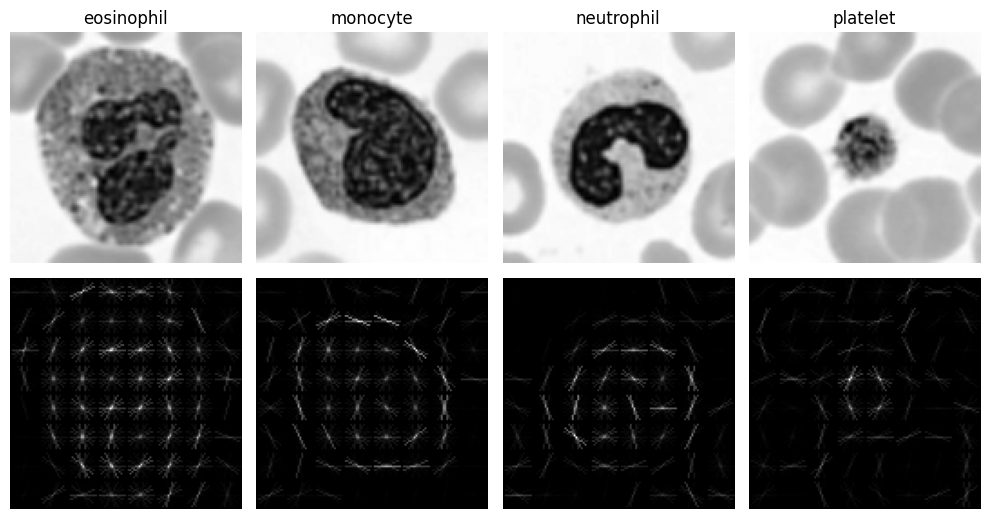

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
for k in range(4):
    i = np.flatnonzero(y["train"] == k)[0]
    _, h = hog(X["train"][i].astype(np.float32) / 255.0, orientations=HOG_ORIENT, pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=HOG_BLOCK, block_norm="L2-Hys", visualize=True)
    axes[0][k].imshow(X["train"][i], cmap="gray"); axes[0][k].set_title(CLASS_NAMES[k]); axes[1][k].imshow(h, cmap="gray")
    axes[0][k].axis("off"); axes[1][k].axis("off")
axes[0][0].set_ylabel("image"); axes[1][0].set_ylabel("HOG")
plt.tight_layout(); plt.show()

### Q2(c) Train the SVM — C chosen on the validation set

Model = `StandardScaler` (fitted on training features only) + `LinearSVC`. The same pipeline is used for HOG and SIFT so the comparison is fair. `C` is chosen from {0.1, 1, 10} by **validation accuracy** (ties: higher macro-F1, then smaller C). The test set is not touched here.

[HOG + SVM] validation results for every C:
   C  val accuracy  val macro-F1
 0.1        0.7167        0.7164
 1.0        0.7167        0.7164
10.0        0.7167        0.7164
[HOG + SVM] chosen C = 0.1

[HOG + SVM] validation accuracy = 0.7167 | macro-F1 = 0.7164
Confusion matrix (rows = true, columns = predicted):
            eosinophil  monocyte  neutrophil  platelet
eosinophil          15        13           2         0
monocyte             5        24           1         0
neutrophil          10         3          17         0
platelet             0         0           0        30


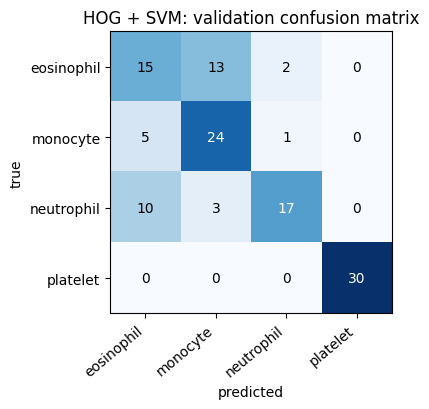

In [ ]:
def fit_and_select(F_train, y_train, F_val, y_val, name):
    results, models = [], {}
    for C in C_GRID:
        pipe = make_pipeline(StandardScaler(), LinearSVC(C=C, dual=True, max_iter=20000, random_state=SEED))
        pipe.fit(F_train, y_train)
        pred = pipe.predict(F_val)
        results.append({"C": C, "val accuracy": accuracy_score(y_val, pred),
                        "val macro-F1": f1_score(y_val, pred, average="macro")})
        models[C] = pipe
    res = pd.DataFrame(results)
    best = res.sort_values(["val accuracy", "val macro-F1", "C"], ascending=[False, False, True]).iloc[0]
    best_C = float(best["C"])
    print(f"[{name}] validation results for every C:"); print(res.round(4).to_string(index=False))
    print(f"[{name}] chosen C = {best_C}")
    return models[best_C], best_C

def report_val(model, F_val, y_val, name):
    pred = model.predict(F_val)
    cm = confusion_matrix(y_val, pred, labels=range(4))
    print(f"\n[{name}] validation accuracy = {accuracy_score(y_val, pred):.4f} | macro-F1 = {f1_score(y_val, pred, average='macro'):.4f}")
    print("Confusion matrix (rows = true, columns = predicted):")
    print(pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))
    fig, ax = plt.subplots(figsize=(4.8, 4.2)); ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(4)); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha="right"); ax.set_yticks(range(4)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(f"{name}: validation confusion matrix"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    plt.tight_layout(); plt.show()
    return cm

hog_model, hog_C = fit_and_select(F_hog["train"], y["train"], F_hog["val"], y["val"], "HOG + SVM")
cm_hog = report_val(hog_model, F_hog["val"], y["val"], "HOG + SVM")

# Q3. SIFT + SVM

### Q3(a) Normal SIFT detection on the training images

In [ ]:
sift = cv2.SIFT_create()

counts, kps_all = [], []
for img in X["train"]:
    kps, des = sift.detectAndCompute(img, None)
    counts.append(len(kps)); kps_all.append(kps)
counts = np.array(counts)

print("Training images:", len(counts))
print(f"Keypoints per image  -> average: {counts.mean():.2f} | minimum: {counts.min()} | maximum: {counts.max()}")
print("Images with zero keypoints:", int((counts == 0).sum()))
print("Average keypoints per class:", {CLASS_NAMES[k]: round(float(counts[y['train'] == k].mean()), 1) for k in range(4)})

Training images: 400
Keypoints per image  -> average: 111.14 | minimum: 10 | maximum: 279
Images with zero keypoints: 0
Average keypoints per class: {'eosinophil': 131.7, 'monocyte': 170.6, 'neutrophil': 107.3, 'platelet': 34.9}


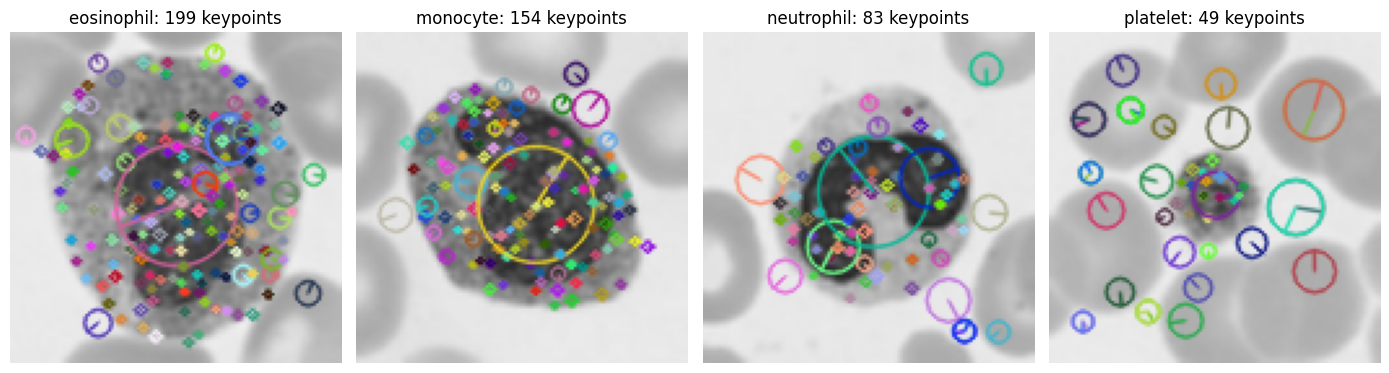

In [ ]:
# keypoints drawn on one image per class
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for k in range(4):
    i = np.flatnonzero(y["train"] == k)[0]
    vis = cv2.drawKeypoints(X["train"][i], kps_all[i], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    axes[k].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); axes[k].axis("off")
    axes[k].set_title(f"{CLASS_NAMES[k]}: {counts[i]} keypoints")
plt.tight_layout(); plt.show()

**Why a different number of keypoints per image is a problem for an SVM:** an SVM needs every image to be one feature vector of the *same length*, but normal SIFT returns an N × 128 descriptor array whose N changes from image to image (see the minimum and maximum printed above), so the images cannot be stacked into one feature matrix (and an image with no keypoints would have no features at all).

### Q3(b) Fix: fixed grid of keypoints

* Grid = 6 × 6 → **36 keypoints**, placed at the centres of a regular 6 × 6 grid over the 128 × 128 image: coordinates (i + 0.5) × 128 / 6 for i = 0 … 5, keypoint size 32, angle 0.
* One SIFT descriptor = **128** numbers.
* Feature length = grid points × 128 = 36 × 128 = **4608**, the same for every image.

In [ ]:
step = IMG / SIFT_GRID
grid_xy = [((c + 0.5) * step, (r + 0.5) * step) for r in range(SIFT_GRID) for c in range(SIFT_GRID)]
grid_kps = [cv2.KeyPoint(float(x), float(yy), 32.0, 0.0) for x, yy in grid_xy]     # x, y, size=32, angle=0

def sift_grid_feat(img_u8):
    _, des = sift.compute(img_u8, grid_kps)
    assert des is not None and des.shape == (SIFT_GRID ** 2, 128), des.shape if des is not None else None
    return des.reshape(-1)

def sift_features(imgs):
    return np.array([sift_grid_feat(i) for i in imgs], dtype=np.float32)

F_sift = {s: sift_features(X[s]) for s in ["train", "val"]}
hand_sift = SIFT_GRID ** 2 * 128
print("Grid keypoint coordinates (x, y):", [(round(a, 1), round(b, 1)) for a, b in grid_xy[:SIFT_GRID]], "... (first row)")
print("SIFT feature matrix (train):", F_sift["train"].shape, "| (val):", F_sift["val"].shape)
print("SIFT feature length from code      :", F_sift["train"].shape[1])
print("SIFT feature length by hand (4608) :", hand_sift)
assert F_sift["train"].shape[1] == hand_sift == 4608

Grid keypoint coordinates (x, y): [(10.7, 10.7), (32.0, 10.7), (53.3, 10.7), (74.7, 10.7), (96.0, 10.7), (117.3, 10.7)] ... (first row)
SIFT feature matrix (train): (400, 4608) | (val): (120, 4608)
SIFT feature length from code      : 4608
SIFT feature length by hand (4608) : 4608


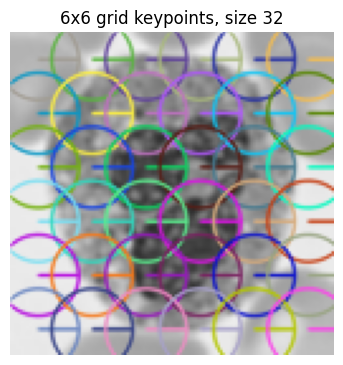

In [ ]:
# the fixed grid drawn on one image
vis = cv2.drawKeypoints(X["train"][0], grid_kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4.2, 4.2)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"{SIFT_GRID}x{SIFT_GRID} grid keypoints, size 32"); plt.show()

### Q3(c) Train the SVM — C chosen on the validation set

[SIFT + SVM] validation results for every C:
   C  val accuracy  val macro-F1
 0.1        0.7333        0.7333
 1.0        0.7333        0.7333
10.0        0.7333        0.7333
[SIFT + SVM] chosen C = 0.1

[SIFT + SVM] validation accuracy = 0.7333 | macro-F1 = 0.7333
Confusion matrix (rows = true, columns = predicted):
            eosinophil  monocyte  neutrophil  platelet
eosinophil          16        10           4         0
monocyte             6        24           0         0
neutrophil           9         3          18         0
platelet             0         0           0        30


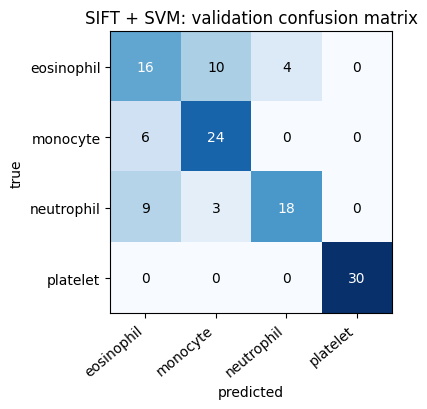

In [ ]:
sift_model, sift_C = fit_and_select(F_sift["train"], y["train"], F_sift["val"], y["val"], "SIFT + SVM")
cm_sift = report_val(sift_model, F_sift["val"], y["val"], "SIFT + SVM")

# Q4. Robustness

### Q4(a) Prediction — written BEFORE running the robustness test

> **Rotation (20°):** I think HOG + SVM will lose more accuracy. HOG puts gradient directions into 9 bins of 20° inside fixed 16 × 16 cells, so rotating the image by 20° moves the edges to different bins and different cells. The SIFT descriptors are computed over bigger windows (size 32) with Gaussian weighting, so they should change more gently.

**Noise (σ = 0.05):** I think HOG + SVM will lose more accuracy. HOG takes gradients directly from pixel differences with no smoothing, so noise creates random gradients, and block normalisation can make them stronger in flat areas. SIFT blurs the image with a Gaussian first, so it should be less affected.

In [ ]:
PRED_ROTATION = "HOG + SVM"     # model I predicted would lose more under rotation (must match the text above)
PRED_NOISE    = "HOG + SVM"     # model I predicted would lose more under noise

### Q4(b) Evaluate the frozen models on the test set

Both models are already trained and are **not refitted**. The change is applied to the 128 × 128 grayscale test images **before** feature extraction.

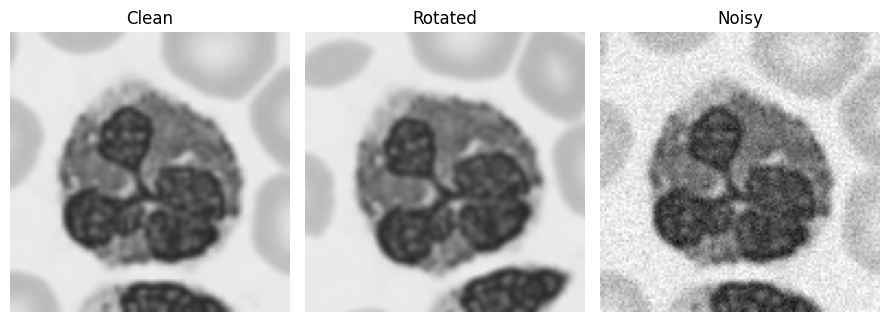

Test images: 120 | rotation = 20 degrees | noise sigma = 0.05


,Clean accuracy,Rotated accuracy,Noisy accuracy
Model,,,
HOG + SVM,0.7417,0.6417,0.2917
SIFT + SVM,0.7917,0.7417,0.7417


In [ ]:
def rotate(img, angle=ROT_ANGLE):
    M = cv2.getRotationMatrix2D((IMG / 2, IMG / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (IMG, IMG), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

noise_rng = np.random.default_rng(SEED)
def add_noise(img, sigma=NOISE_SIGMA):
    x = img.astype(np.float32) / 255.0                      # scale to 0..1
    x = np.clip(x + noise_rng.normal(0.0, sigma, x.shape), 0.0, 1.0)
    return np.round(x * 255).astype(np.uint8)

X_test, y_test = X["test"], y["test"]
test_sets = {"Clean": X_test,
             "Rotated": np.stack([rotate(i) for i in X_test]),
             "Noisy": np.stack([add_noise(i) for i in X_test])}

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, (name, arr) in zip(axes, test_sets.items()):
    ax.imshow(arr[0], cmap="gray", vmin=0, vmax=255); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()

acc = {"HOG + SVM": {}, "SIFT + SVM": {}}
for cond, imgs in test_sets.items():
    acc["HOG + SVM"][cond] = accuracy_score(y_test, hog_model.predict(hog_features(imgs)))
    acc["SIFT + SVM"][cond] = accuracy_score(y_test, sift_model.predict(sift_features(imgs)))

table = pd.DataFrame(acc).T[["Clean", "Rotated", "Noisy"]]
table.index.name = "Model"
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
print(f"Test images: {len(y_test)} | rotation = {ROT_ANGLE} degrees | noise sigma = {NOISE_SIGMA}")
table.round(4)

### Q4(c) Was the prediction correct?

The sentences below are generated from the table above (so every number comes from an output).

In [ ]:
d_rot = {m: table.loc[m, "Clean accuracy"] - table.loc[m, "Rotated accuracy"] for m in table.index}
d_noi = {m: table.loc[m, "Clean accuracy"] - table.loc[m, "Noisy accuracy"] for m in table.index}
worse_rot = max(d_rot, key=d_rot.get); worse_noi = max(d_noi, key=d_noi.get)

print(f"1. Under rotation, HOG + SVM went from {table.loc['HOG + SVM','Clean accuracy']:.3f} to {table.loc['HOG + SVM','Rotated accuracy']:.3f} "
      f"(change {-d_rot['HOG + SVM']:+.3f}) and SIFT + SVM from {table.loc['SIFT + SVM','Clean accuracy']:.3f} to {table.loc['SIFT + SVM','Rotated accuracy']:.3f} "
      f"(change {-d_rot['SIFT + SVM']:+.3f}), so {worse_rot} lost more; my prediction ({PRED_ROTATION}) was {'CORRECT' if worse_rot == PRED_ROTATION else 'WRONG'}.")
print(f"2. Under noise, HOG + SVM went from {table.loc['HOG + SVM','Clean accuracy']:.3f} to {table.loc['HOG + SVM','Noisy accuracy']:.3f} "
      f"(change {-d_noi['HOG + SVM']:+.3f}) and SIFT + SVM from {table.loc['SIFT + SVM','Clean accuracy']:.3f} to {table.loc['SIFT + SVM','Noisy accuracy']:.3f} "
      f"(change {-d_noi['SIFT + SVM']:+.3f}), so {worse_noi} lost more; my prediction ({PRED_NOISE}) was {'CORRECT' if worse_noi == PRED_NOISE else 'WRONG'}.")
more_reliable = max(table.index, key=lambda m: table.loc[m, ['Rotated accuracy', 'Noisy accuracy']].mean())
print(f"3. Averaged over the two perturbed cases, {more_reliable} kept the higher accuracy "
      f"({table.loc[more_reliable, ['Rotated accuracy','Noisy accuracy']].mean():.3f}), so it was the more reliable pipeline in this experiment "
      f"(test set of only {len(y_test)} images, so differences of a few images are within chance).")

1. Under rotation, HOG + SVM went from 0.742 to 0.642 (change -0.100) and SIFT + SVM from 0.792 to 0.742 (change -0.050), so HOG + SVM lost more; my prediction (HOG + SVM) was CORRECT.
2. Under noise, HOG + SVM went from 0.742 to 0.292 (change -0.450) and SIFT + SVM from 0.792 to 0.742 (change -0.050), so HOG + SVM lost more; my prediction (HOG + SVM) was CORRECT.
3. Averaged over the two perturbed cases, SIFT + SVM kept the higher accuracy (0.742), so it was the more reliable pipeline in this experiment (test set of only 120 images, so differences of a few images are within chance).


**Q4(c) Answer.** My prediction was correct for both rotation and noise. Under rotation HOG + SVM fell from 0.742 to 0.642 (−0.100) and SIFT + SVM from 0.792 to 0.742 (−0.050), and under noise HOG + SVM fell from 0.742 to 0.292 (−0.450) while SIFT + SVM only fell to 0.742 (−0.050). This fits my reasoning that HOG, which uses raw pixel gradients, is more sensitive than SIFT, which smooths the image first, although the rotation gap is only 6 of the 120 test images and could partly be chance, while the noise gap is large.

# Q5. Short answers and AI log (3 marks)

### Q5(a) Why does HOG use block normalisation?

Gradient magnitudes change with lighting and contrast, so the raw cell histograms of the same structure can have very different sizes in bright and dark parts of an image. HOG groups neighbouring cells into overlapping blocks and normalises each block (here L2-Hys), which makes the descriptor much less sensitive to local illumination and contrast changes. Because blocks overlap, each cell is normalised several times in different contexts, which also gives some robustness to small shifts.

### Q5(b) Why is it wrong to choose C using the test set?

The test set is meant to estimate how the final model performs on completely unseen data. If C is picked by looking at test accuracy, the test data has influenced the model, so the reported test accuracy becomes optimistic and no longer an honest estimate. C must be chosen on a separate validation set, and the test set used once at the end.

### Q5(c) Which two classes were confused most, and why might grayscale make this harder?

Computed from the **validation** confusion matrices of Q2 and Q3 (the test set is only used in Q4).

In [ ]:
def top_pair(cm):
    pairs = {(i, j): int(cm[i, j] + cm[j, i]) for i in range(4) for j in range(i + 1, 4)}
    (i, j), n = max(pairs.items(), key=lambda kv: kv[1])
    return CLASS_NAMES[i], CLASS_NAMES[j], n

for name, cm in [("HOG + SVM", cm_hog), ("SIFT + SVM", cm_sift), ("both models combined", cm_hog + cm_sift)]:
    a, b, n = top_pair(cm)
    print(f"{name:22s}: most confused pair = {a} <-> {b}  ({n} validation errors between them)")

a, b, n = top_pair(cm_hog + cm_sift)
reasons = {
    frozenset(["eosinophil", "neutrophil"]): "both are granulocytes of similar size with lobed nuclei; the clearest difference is the bright red-orange granules of eosinophils, which is a colour cue that grayscale removes",
    frozenset(["monocyte", "neutrophil"]): "both are white cells with lobed/indented nuclei and similar size; they differ mostly in nucleus-to-cytoplasm staining colour, and grayscale reduces that contrast",
    frozenset(["eosinophil", "monocyte"]): "both are large white cells and the main eosinophil cue is the red-orange granule colour, which grayscale removes, leaving mostly nucleus shape and texture",
}
generic = "these classes are distinguished mainly by stain colour and fine granule texture, and grayscale removes the colour information, so only shape and texture remain"
print(f"\nAnswer: the models confused {a} and {b} most. Grayscale may make this harder because "
      f"{reasons.get(frozenset([a, b]), generic)}.")

HOG + SVM             : most confused pair = eosinophil <-> monocyte  (18 validation errors between them)
SIFT + SVM            : most confused pair = eosinophil <-> monocyte  (16 validation errors between them)
both models combined  : most confused pair = eosinophil <-> monocyte  (34 validation errors between them)

Answer: the models confused eosinophil and monocyte most. Grayscale may make this harder because both are large white cells and the main eosinophil cue is the red-orange granule colour, which grayscale removes, leaving mostly nucleus shape and texture.


**Q5(c) Answer.** Both models confused eosinophil and monocyte most on the validation set (HOG + SVM: 18 errors, SIFT + SVM: 16 errors, 34 combined). Eosinophils are mainly recognised by their red-orange granules, and that colour information is removed when the image is converted to grayscale, so only nucleus shape and texture are left, which look similar to monocytes.

### Q5(d) AI log

| # | Prompt (one line) | What I changed | How I checked the result was correct |
|---|---|---|---|
| 1 | "Write the HOG vs SIFT blood-cell lab mid exam notebook for registration 007 (seed 7, HOG 16×16, SIFT 6×6 grid)." | Ran it in Colab with my own settings; rewrote the Q4(a) wording and wrote the Q4(c) and Q5(c) answers myself. | Printed the derived settings (seed 7, HOG 16×16, SIFT 6×6 = 36 keypoints); checked split shapes and class counts (400/120/120) in Q1 and the example grid. |
| 2 | "How do I get a fixed-length SIFT feature using a grid of keypoints and `sift.compute`?" | Used the grid-cell centres, keypoint size 32 and angle 0. | Printed the feature matrix shape and asserted length = 36 × 128 = 4608; drew the grid on an image. |
| 3 | "Explain every line of the notebook code." | Read the explanation and made sure I can explain the grid keypoints, `fit_and_select`, `rotate` and `add_noise` cells. | Compared my Q4 prediction with the printed table; HOG feature length 1764 matched my hand calculation (49 blocks × 36). |
